<a href="https://colab.research.google.com/github/geRSun1/Computer_version/blob/main/CV_buoi1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Ex1 Tải một ảnh khác (ảnh cá nhân hoặc ảnh từ dataset) và lặp lại các thí nghiệm.

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# For inline plots
%matplotlib inline


Saving 1.jpg to 1.jpg


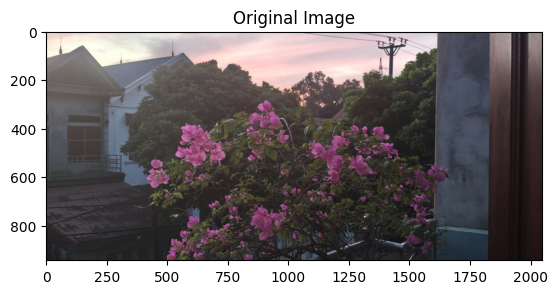

In [ ]:
# Load image
from google.colab import files
uploaded = files.upload()

img = cv2.imread("1.jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
# plt.axis("off")
plt.show()

In [ ]:
pip install opencv-python

In [ ]:
# Show shape and a few pixel values
print("Image shape (H, W, C):", img_rgb.shape) # height, width, channel(kênh) ở đây là 3 rgb
print("Pixel at (50,50):", img_rgb[50,50])  # R,G,B values

Image shape (H, W, C): (944, 2048, 3)
Pixel at (50,50): [254 242 228]


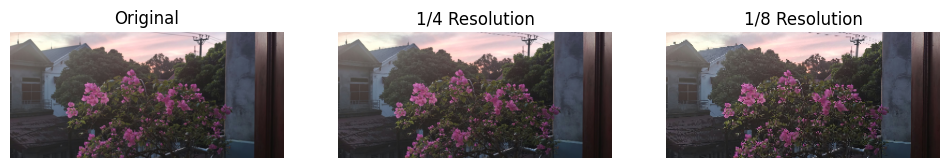

In [ ]:
def downsample(img, factor):
    h, w = img.shape[:2]#Lấy ra chiều cao (h) và chiều rộng (w) của bức ảnh ban đầu.
    return cv2.resize(img, (w//factor, h//factor), interpolation=cv2.INTER_NEAREST)
    #resize Dùng hàm thay đổi kích thước của OpenCV để thu nhỏ ảnh.
    #Tính toán kích thước mới bằng cách chia chiều rộng và chiều cao cho hệ số factor (tỷ lệ thu nhỏ).
    #interpolation=cv2.INTER_NEAREST: Sử dụng phương pháp nội suy láng giềng gần nhất (Nearest Neighbor) để chọn lại điểm ảnh khi thu nhỏ. Phương pháp này giữ lại các giá trị gốc thô ráp, thường làm ảnh bị vỡ hạt (pixelated) rõ rệt.
fig, axes = plt.subplots(1,3, figsize=(12,4))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(downsample(img_rgb, 4))
axes[1].set_title("1/4 Resolution")
axes[1].axis("off")

axes[2].imshow(downsample(img_rgb, 8))
axes[2].set_title("1/8 Resolution")
axes[2].axis("off")
plt.show()


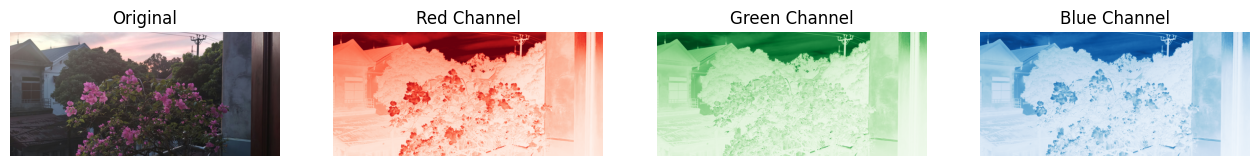

In [ ]:
r, g, b = cv2.split(img_rgb)

fig, axes = plt.subplots(1,4, figsize=(16,4))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(r, cmap="Reds")
axes[1].set_title("Red Channel")
axes[1].axis("off")

axes[2].imshow(g, cmap="Greens")
axes[2].set_title("Green Channel")
axes[2].axis("off")

axes[3].imshow(b, cmap="Blues")
axes[3].set_title("Blue Channel")
axes[3].axis("off")
plt.show()


#ex2 Thử các hệ số lấy mẫu khác nhau (ví dụ: 2, 4, 10) và quan sát sự khác biệt.

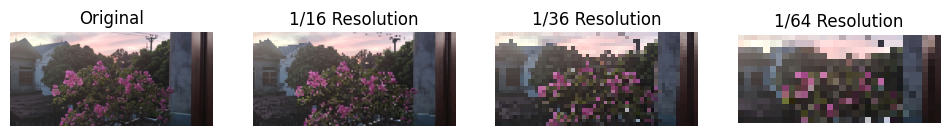

In [ ]:

def downsample(img, factor):
    h, w = img.shape[:2]
    return cv2.resize(img, (w//factor, h//factor), interpolation=cv2.INTER_NEAREST)
fig, axes = plt.subplots(1,4, figsize=(12,4))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(downsample(img_rgb, 16))
axes[1].set_title("1/16 Resolution")
axes[1].axis("off")

axes[2].imshow(downsample(img_rgb, 36))
axes[2].set_title("1/36 Resolution")
axes[2].axis("off")

axes[3].imshow(downsample(img_rgb, 64))
axes[3].set_title("1/64 Resolution")
axes[3].axis("off")
plt.show()


 Ex3 Lượng tử hóa ảnh xuống còn 2 mức xám (đen/trắng). So sánh với phương pháp ngưỡng hóa (thresholding) đơn giản.

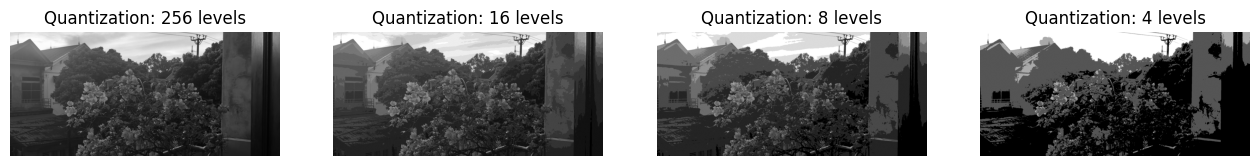

In [ ]:
def quantize_gray(img, levels):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    max_val = 256
    step = max_val // levels
    return (gray // step) * step

levels = [256, 16, 8, 4]
fig, axes = plt.subplots(1, len(levels), figsize=(16,4))
for i, l in enumerate(levels):
    q = quantize_gray(img_rgb, l)
    axes[i].imshow(q, cmap="gray")
    axes[i].set_title(f"Quantization: {l} levels")
    axes[i].axis("off")
plt.show()

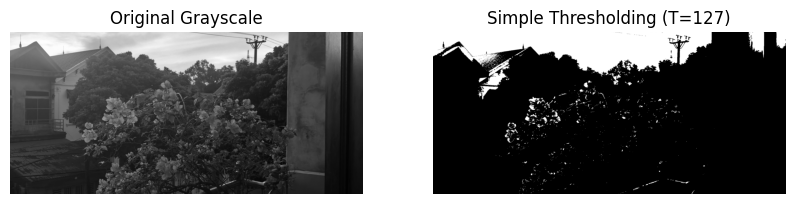

In [ ]:
# 1. Đọc ảnh màu và chuyển sang ảnh xám
img = cv2.imread("1.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Áp dụng ngưỡng hóa đơn giản (Simple Thresholding)
# - thresh = 127: Giá trị ngưỡng phân chia
# - maxval = 255: Giá trị gán tối đa (màu trắng) nếu vượt quá ngưỡng
# - cv2.THRESH_BINARY: Kiểu ngưỡng hóa nhị phân (chỉ lấy 0 hoặc maxval)
_, thresh_binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# 3. Hiển thị kết quả so sánh giữa ảnh xám gốc và ảnh sau khi ngưỡng hóa
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Ảnh xám ban đầu
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Grayscale")
axes[0].axis("off")

# Ảnh sau khi ngưỡng hóa
axes[1].imshow(thresh_binary, cmap="gray")
axes[1].set_title("Simple Thresholding (T=127)")
axes[1].axis("off")

plt.show()

Ex4: Giải thích cách việc lấy mẫu và lượng tử hóa ảnh hưởng đến chất lượng ảnh.

1) Lấy mẫu liên quan đến việc chia không gian bức ảnh thành một lưới các điểm ảnh (pixel) quyết định độ phân giải không gian (chiều cao và chiều rộng của ảnh).


*  **Khi lấy mẫu dày đặc (mật độ pixel cao):**
  
  Ảnh giữ lại được vô số chi tiết nhỏ, đường nét sắc sảo, biên cạnh rõ ràng.

Nhược điểm: Kích thước ma trận ảnh lớn, tốn nhiều bộ nhớ lưu trữ và thời gian xử lý.

* **Khi lấy mẫu thưa thớt (giảm độ phân giải / downsampling):**

Số lượng pixel bị thu hẹp lại (như các ví dụ giảm 4 lần, 8 lần, hoặc 64 lần mà bạn đã thực hành).

Hậu quả chất lượng: Ảnh bị vỡ hạt (pixelation), các đường cong hay đường chéo bị răng cưa (aliasing), các chi tiết nhỏ bị nhòe và biến mất hoàn toàn vì không đủ số lượng pixel để tái tạo.

2) Lượng tử hóa liên quan đến việc chia nhỏ các dải giá trị cường độ ánh sáng liên tục thành một số hữu hạn các mức xám hoặc mức màu – quyết định độ sâu màu (bit-depth) của ảnh.

**Khi lượng tử hóa với số mức lớn (ví dụ: 256 mức chuẩn):**

Các bước chuyển đổi màu sắc và ánh sáng diễn ra rất mịn màng, mượt mà (smooth gradients), tái hiện chính xác độ sâu và bóng đổ của vật thể thực tế.

**Khi lượng tử hóa với số mức thấp (ví dụ: 16, 8, hoặc 4 mức):**

Dải giá trị bị bóp nghẹt thành các bậc thang thô cứng.

Hậu quả chất lượng: Xuất hiện hiện tượng giả đường đồng mức (false contouring) — thay vì thấy vùng da hoặc bầu trời chuyển màu mượt, ta sẽ thấy các mảng màu bị tách thành từng khoanh bậc thang rõ rệt, làm mất đi các chi tiết tinh tế về mặt sắc thái.

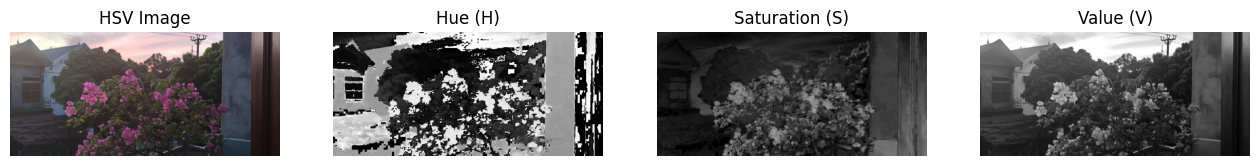

In [ ]:
import cv2
import matplotlib.pyplot as plt

# 1. Chuyển ảnh từ RGB sang không gian màu HSV
# OpenCV đọc mặc định là BGR, nên nếu bạn dùng img_rgb thì cần chuyển qua BGR trước hoặc dùng trực tiếp từ ảnh BGR gốc.
# Ở đây ta giả sử bạn đang dùng img_rgb, ta chuyển nó về BGR rồi sang HSV chuẩn của OpenCV:
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# 2. Tách các kênh màu riêng biệt (H, S, V)
h, s, v = cv2.split(img_hsv)

# 3. Hiển thị ảnh HSV gốc và 3 kênh thành phần
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Ảnh HSV tổng hợp (hiển thị qua OpenCV/Matplotlib sẽ cần lưu ý dải màu, ở đây ta hiển thị dạng trực quan)
axes[0].imshow(cv2.cvtColor(img_hsv, cv2.COLOR_HSV2RGB))
axes[0].set_title("HSV Image")
axes[0].axis("off")

# Kênh Hue (Sắc độ)
axes[1].imshow(h, cmap="gray")
axes[1].set_title("Hue (H)")
axes[1].axis("off")

# Kênh Saturation (Độ bão hòa)
axes[2].imshow(s, cmap="gray")
axes[2].set_title("Saturation (S)")
axes[2].axis("off")

# Kênh Value (Độ sáng)
axes[3].imshow(v, cmap="gray")
axes[3].set_title("Value (V)")
axes[3].axis("off")

plt.show()